# Tests

In [1]:
# Import packages.
import demes
import demesdraw
import matplotlib
from matplotlib import pyplot as plt
import msprime
import numpy as np
import pandas as pd
import tskit

# Initialize my pandas preferences.
pd.set_option("display.max_columns", None)

# Print the version.
print("demes", demes.__version__)
print("demesdraw", demesdraw.__version__)
print("matplotlib", matplotlib.__version__)
print("msprime", msprime.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)
print("tskit", tskit.__version__)

demes 0.2.3
demesdraw 0.4.0
matplotlib 3.10.6
msprime 1.3.4
numpy 2.3.3
pandas 2.3.3
tskit 0.6.4


## Q: Are the iterations and length columns being recorded?
See `tests/README.md` for the commands.

In [2]:
# Load and display the outputs.
Demography1_columns_test_precommit_df = pd.read_csv(
    "Demography1_columns_test_precommit.txt", sep="\t"
)
PapuansOutOfAfrica_10J19_columns_test_precommit_df = pd.read_csv(
    "PapuansOutOfAfrica_10J19_columns_test_precommit.txt", sep="\t"
)

print("#***# Demography1 #***#")
display(Demography1_columns_test_precommit_df.head())

print("#***# PapuansOutOfAfrica_10J19 #***#")
display(PapuansOutOfAfrica_10J19_columns_test_precommit_df.head())

#***# Demography1 #***#


,iteration,haplotype,pop,start,end,length,admix_event,admixtime,snps,Seq_DEN
0,0,Ingroup,126443,158290,Distant_DEN>Ingroup,1551.7,7,5,NaN,NaN
1,0,Ingroup,206139,223580,Distant_DEN>Ingroup,1551.7,8,4,NaN,NaN
2,0,Ingroup,1006542,1007305,Distant_DEN>Ingroup,1551.7,0,0,NaN,NaN
3,0,Ingroup,1180240,1290919,Distant_DEN>Ingroup,1551.7,27,13,NaN,NaN
4,0,Ingroup,1342407,1344305,Distant_DEN>Ingroup,1551.7,2,0,NaN,NaN


#***# PapuansOutOfAfrica_10J19 #***#


,iteration,haplotype,pop,start,end,length,admix_event,admixtime,snps,DenA,NeaA
0,0,Papuan,244738,253672,CHB>Papuan,1656.3,1,0,0,NaN,NaN
1,0,Papuan,359691,459872,CHB>Papuan,1656.3,32,0,0,NaN,NaN
2,0,Papuan,561083,572585,CHB>Papuan,1656.3,2,0,0,NaN,NaN
3,0,Papuan,845473,918344,CHB>Papuan,1409.3,19,0,0,NaN,NaN
4,0,Papuan,1526912,1706283,CHB>Papuan,386.5,46,0,8,NaN,NaN


In [3]:
# Sanity check the number of iterations.
# Expected output: [0, 1, 2, 3, 4]
print(
    f"Demography1 iterations:{Demography1_columns_test_precommit_df.iteration.unique()}"
)
print(
    f"PapuansOutOfAfrica_10J19 iterations:{PapuansOutOfAfrica_10J19_columns_test_precommit_df.iteration.unique()}"
)

Demography1 iterations:[0 1]
PapuansOutOfAfrica_10J19 iterations:[ 0  1  2  3  4  5 10 11]


In [4]:
# Sanity check the segment lengths.
# Note that based on the cells above the end = start and start = pop.
Demography1_columns_test_precommit_df["end_minus_start"] = (
    Demography1_columns_test_precommit_df["start"]
    - Demography1_columns_test_precommit_df["pop"]
)
PapuansOutOfAfrica_10J19_columns_test_precommit_df["end_minus_start"] = (
    PapuansOutOfAfrica_10J19_columns_test_precommit_df["start"]
    - PapuansOutOfAfrica_10J19_columns_test_precommit_df["pop"]
)


print(
    f"Demography1 does end - start = length?: {Demography1_columns_test_precommit_df['end_minus_start'].equals(Demography1_columns_test_precommit_df['length'])}"
)
print(
    f"PapuansOutOfAfrica_10J19 does end - start = length?: {PapuansOutOfAfrica_10J19_columns_test_precommit_df['end_minus_start'].equals(PapuansOutOfAfrica_10J19_columns_test_precommit_df['length'])}"
)

Demography1 does end - start = length?: False
PapuansOutOfAfrica_10J19 does end - start = length?: False


A: No, neither columns are being recorded.
Based on commit `104fa43`, the culprit seems to be lines 268-286, where it is clear to see that neither are being recorded:
```python
        for (haplotype, pop, start, end,  admix_event, admixtime) in introgressed_segments:
            

            OUTPUT = [haplotype, pop, start, end,  admix_event, admixtime]
            ID = f'{haplotype}|{pop}|{admix_event}|{admixtime}|{start}|{end}'
            
            snps = introgressed_segments_dict[ID, 'snps']
            shared = [str(introgressed_segments_dict[ID, seq_arch]) for seq_arch in ARCHAIC_GENOME_SAMPLES]
            OUTPUT += [snps, '\t'.join(shared)]

            if args.extrainfo:
                snp_ages = ','.join([x for x in introgressed_snp_ages[ID, 'snp_ages']])
                snp_position = ','.join([x for x in introgressed_snp_ages[ID, 'snp_positions']])
                matches = ','.join([x for x in introgressed_snp_ages[ID, 'match']])

                OUTPUT += [snp_position, snp_ages, matches]

            if any([keyword in admix_event for keyword in keywords]):
                print(*OUTPUT, sep = '\t', file = out)
```
Luckily, Skov writes nice code so the fix is easy:
```python
        for (haplotype, pop, start, end,  admix_event, admixtime) in introgressed_segments:
            

            OUTPUT = [iteration, haplotype, pop, start, end, end - start, admix_event, admixtime]
            ID = f'{haplotype}|{pop}|{admix_event}|{admixtime}|{start}|{end}'
            
            snps = introgressed_segments_dict[ID, 'snps']
            shared = [str(introgressed_segments_dict[ID, seq_arch]) for seq_arch in ARCHAIC_GENOME_SAMPLES]
            OUTPUT += [snps, '\t'.join(shared)]

            if args.extrainfo:
                snp_ages = ','.join([x for x in introgressed_snp_ages[ID, 'snp_ages']])
                snp_position = ','.join([x for x in introgressed_snp_ages[ID, 'snp_positions']])
                matches = ','.join([x for x in introgressed_snp_ages[ID, 'match']])

                OUTPUT += [snp_position, snp_ages, matches]

            if any([keyword in admix_event for keyword in keywords]):
                print(*OUTPUT, sep = '\t', file = out)
```

Now let's see if the iterations and length columns are being recorded in the postcommit files.

In [5]:
# Load and display the outputs.
Demography1_columns_test_postcommit_df = pd.read_csv(
    "Demography1_columns_test_postcommit.txt", sep="\t"
)
PapuansOutOfAfrica_10J19_columns_test_postcommit_df = pd.read_csv(
    "PapuansOutOfAfrica_10J19_columns_test_postcommit.txt", sep="\t"
)

print("#***# Demography1 #***#")
display(Demography1_columns_test_postcommit_df.head())

print("#***# PapuansOutOfAfrica_10J19 #***#")
display(PapuansOutOfAfrica_10J19_columns_test_postcommit_df.head())

#***# Demography1 #***#


,iteration,haplotype,pop,start,end,length,admix_event,admixtime,snps,Seq_DEN
0,0,0,Ingroup,126443,158290,31847,Distant_DEN>Ingroup,1551.7,7,5
1,0,0,Ingroup,206139,223580,17441,Distant_DEN>Ingroup,1551.7,8,4
2,0,0,Ingroup,1006542,1007305,763,Distant_DEN>Ingroup,1551.7,0,0
3,0,0,Ingroup,1180240,1290919,110679,Distant_DEN>Ingroup,1551.7,27,13
4,0,0,Ingroup,1342407,1344305,1898,Distant_DEN>Ingroup,1551.7,2,0


#***# PapuansOutOfAfrica_10J19 #***#


,iteration,haplotype,pop,start,end,length,admix_event,admixtime,snps,DenA,NeaA
0,0,0,Papuan,244738,253672,8934,CHB>Papuan,1656.3,1,0,0
1,0,0,Papuan,359691,459872,100181,CHB>Papuan,1656.3,32,0,0
2,0,0,Papuan,561083,572585,11502,CHB>Papuan,1656.3,2,0,0
3,0,0,Papuan,845473,918344,72871,CHB>Papuan,1409.3,19,0,0
4,0,0,Papuan,1526912,1706283,179371,CHB>Papuan,386.5,46,0,8


In [6]:
# Sanity check the number of iterations.
# Expected output: [0, 1, 2, 3, 4]
print(
    f"Demography1 iterations:{Demography1_columns_test_postcommit_df.iteration.unique()}"
)
print(
    f"PapuansOutOfAfrica_10J19 iterations:{PapuansOutOfAfrica_10J19_columns_test_postcommit_df.iteration.unique()}"
)

Demography1 iterations:[0 1 2 3 4]
PapuansOutOfAfrica_10J19 iterations:[0 1 2 3 4]


In [7]:
# Sanity check the segment lengths.
Demography1_columns_test_postcommit_df["end_minus_start"] = (
    Demography1_columns_test_postcommit_df["end"]
    - Demography1_columns_test_postcommit_df["start"]
)
PapuansOutOfAfrica_10J19_columns_test_postcommit_df["end_minus_start"] = (
    PapuansOutOfAfrica_10J19_columns_test_postcommit_df["end"]
    - PapuansOutOfAfrica_10J19_columns_test_postcommit_df["start"]
)


print(
    f"Demography1 does end - start = length?: {Demography1_columns_test_postcommit_df['end_minus_start'].equals(Demography1_columns_test_postcommit_df['length'])}"
)
print(
    f"PapuansOutOfAfrica_10J19 does end - start = length?: {PapuansOutOfAfrica_10J19_columns_test_postcommit_df['end_minus_start'].equals(PapuansOutOfAfrica_10J19_columns_test_postcommit_df['length'])}"
)

Demography1 does end - start = length?: True
PapuansOutOfAfrica_10J19 does end - start = length?: True


## Q: Do Skov and I call the same segments?
First I will define my personal segment calling functions.

In [8]:
# Define a function to extract the sorted migration events.
def extract_sorted_migration_events(
    ts,
    donor_pop,
    recipient_pop,
    mig_time,
    interval_type="open",
):
    """Extract the sorted migration events from a tree-sequence.

    Args:
        ts (tskit.TreeSequence): A tree-sequence simulated with record_migrations=True.
        donor_pop (int): Population ID of the donor population (i.e., the "destination" wrt to msprime).
        recipient_pop (int): Population ID of the recipient population (i.e., the "source" wrt to msprime).
        mig_time (float | tuple of length 2): The migration time or a tuple consisting of the lower and upper time bounds of the migration event, i.e., (mig_time_lower, mig_time_upper).
        interval_type (str, optional): The type of interval to use. Options are:
            - "left-closed": [mig_time_lower, mig_time_upper)
            - "left-open": (mig_time_lower, mig_time_upper]
            - "closed": [mig_time_lower, mig_time_upper]
            - "open": (mig_time_lower, mig_time_upper)

    Raises:
        ValueError: If the migration event's time lower bound is not less than the upper bound or if the interval type is invalid.

    Returns:
        list: A list of the sorted migration objects.
    """
    # If the migration time is a tuple.
    if isinstance(mig_time, tuple):
        # Extract the lower and upper bounds.
        mig_time_lower, mig_time_upper = mig_time
        # Check that the bounds are valid.
        if mig_time_lower >= mig_time_upper:
            raise ValueError(
                f"The lower time bound must be < the upper time bound, but got mig_time_lower = {mig_time_lower} and mig_time_upper = {mig_time_upper}."
            )
        # Create a mask for the introgression time.
        if interval_type == "left-closed":
            is_mig_time = (ts.migrations_time >= mig_time_lower) & (
                ts.migrations_time < mig_time_upper
            )
        elif interval_type == "left-open":
            is_mig_time = (ts.migrations_time > mig_time_lower) & (
                ts.migrations_time <= mig_time_upper
            )
        elif interval_type == "closed":
            is_mig_time = (ts.migrations_time >= mig_time_lower) & (
                ts.migrations_time <= mig_time_upper
            )
        elif interval_type == "open":
            is_mig_time = (ts.migrations_time > mig_time_lower) & (
                ts.migrations_time < mig_time_upper
            )
        else:
            raise ValueError(
                f"Invalid interval type: {interval_type}. Must be one of: 'left-closed', 'left-open', 'closed', 'open'."
            )
    else:
        # Create a mask for the introgression time.
        is_mig_time = ts.migrations_time == mig_time
    # Create a mask for the specified migration event.
    is_event = (
        (ts.migrations_dest == donor_pop)
        & (ts.migrations_source == recipient_pop)
        & is_mig_time
    )
    # Extract the indices of the migration records.
    mig_idx = np.flatnonzero(is_event)
    # If there are no migration records, return an empty list.
    if len(mig_idx) == 0:
        return []
    # Extract and sort the left coordinates for the migrating records.
    sorted_idx = np.argsort(ts.migrations_left[mig_idx], kind="stable")
    return [ts.migration(mig_id) for mig_id in mig_idx[sorted_idx]]


# Define a function to find the trees with migrating ancestry segments.
def find_migrating_trees(
    ts,
    sample_pop_list,
    donor_pop,
    recipient_pop,
    mig_time,
    interval_type="open",
):
    """Record every (haplotype, marginal tree, migration record) overlap for one migration event.

    Args:
        ts (tskit.TreeSequence): A tree-sequence simulated with record_migrations=True.
        sample_pop_list (list): Population IDs whose sample haplotypes are reported.
        donor_pop (int): Population ID of the donor population (i.e., the "destination" wrt to msprime).
        recipient_pop (int): Population ID of the recipient population (i.e., the "source" wrt to msprime).
        mig_time (float | tuple of length 2): The migration time or a tuple consisting of the lower and upper time bounds of the migration event.
        interval_type (str, optional): The type of interval to use.

    Returns:
        pandas.DataFrame: One row per overlap, with the following columns:
            - hap_id: The node ID of the haplotype.
            - t_idx: The index of the marginal tree.
            - t_l: The left coordinate of the marginal tree.
            - t_r: The right coordinate of the marginal tree.
            - t_span: The span of the marginal tree.
            - m_id: The index of the migration record.
            - m_node: The node ID of the migrating segment.
            - m_l: The left coordinate of the migrating segment.
            - m_r: The right coordinate of the migrating segment.
            - m_span: The span of the migrating segment.
            - o_len: The length of the overlap wrt the marginal tree.
            - o_perct: The fraction of the marginal tree's span that is overlapped by the migrating segment.
    """
    # Extract the left-sorted migration records.
    migs = extract_sorted_migration_events(
        ts=ts,
        donor_pop=donor_pop,
        recipient_pop=recipient_pop,
        mig_time=mig_time,
        interval_type=interval_type,
    )
    # Initialize a dictionary.
    mig_dicc = {
        "hap_id": [],
        "t_idx": [],
        "t_l": [],
        "t_r": [],
        "t_span": [],
        "m_id": [],
        "m_node": [],
        "m_l": [],
        "m_r": [],
        "m_span": [],
        "o_len": [],
        "o_perct": [],
    }
    # If there are no migration records, return an empty dataframe.
    if not migs:
        return pd.DataFrame(mig_dicc)

    # Extract the right-sorted indices.
    sorted_right_idx = np.argsort([m.right for m in migs])
    # Collect the sample haplotypes of interest.
    sample_haplotypes = set()
    for sample_pop in sample_pop_list:
        sample_haplotypes.update(ts.samples(sample_pop))
    # Initialize pointers for the start and end of the migrating segments.
    c_left_idx, c_right_idx = 0, 0
    # Initialize a dictionary to store the current migrating segments.
    c_segs = {}
    # Determine the number of migration records.
    n_records = len(migs)

    # Iterate through the tree-sequence.
    for tree in ts.trees():
        # Extract the marginal tree's coordinates.
        tree_left, tree_right = tree.interval

        # Accumulate the migrating segments whose start coordinate (mig_lefts) comes before the marginal tree's end coordinate (tree_right).
        while (c_left_idx < n_records) and (migs[c_left_idx].left < tree_right):
            # Update the current segments.
            c_segs[migs[c_left_idx].id] = migs[c_left_idx]
            # Increment the left index.
            c_left_idx += 1

        # Remove the migrating segments whose end coordinate (mig_rights) comes before the marginal tree's start coordinate (tree_left).
        while (c_right_idx < n_records) and (
            migs[sorted_right_idx[c_right_idx]].right <= tree_left
        ):  # Note: <= because the right coordinate for the migrating segment is not included in the marginal tree's half open interval.
            # Remove the segment.
            c_segs.pop(migs[sorted_right_idx[c_right_idx]].id, None)
            # Increment the right index.
            c_right_idx += 1

        # If there are no migrating segments, continue to the next tree.
        if not c_segs:
            continue

        # Iterate through the migrating segments that have been accumulated.
        for mig in c_segs.values():
            # Compute the overlap length.
            o_len = min(tree_right, mig.right) - max(tree_left, mig.left)
            # If there is no overlap, continue to the next migrating segment.
            if o_len <= 0:
                continue

            # Extract the leaves in the subtree rooted at the migrating node.
            leaves = set(tree.leaves(mig.node))
            # Find the intersection of the leaves and the sample haplotypes.
            mig_sample_children = sample_haplotypes & leaves
            # If none of the sample haplotypes are children of the migrating segment, continue to the next migrating segment.
            if not mig_sample_children:
                continue

            # If the sample haplotype is a leaf in the subtree rooted at the migrating node then it is recorded.
            for sample_hap in mig_sample_children:
                mig_dicc["hap_id"].append(sample_hap)
                mig_dicc["t_idx"].append(tree.index)
                mig_dicc["t_l"].append(tree_left)
                mig_dicc["t_r"].append(tree_right)
                mig_dicc["t_span"].append(tree_right - tree_left)
                mig_dicc["m_id"].append(mig.id)
                mig_dicc["m_node"].append(mig.node)
                mig_dicc["m_l"].append(mig.left)
                mig_dicc["m_r"].append(mig.right)
                mig_dicc["m_span"].append(mig.right - mig.left)
                mig_dicc["o_len"].append(o_len)
                mig_dicc["o_perct"].append(o_len / (tree_right - tree_left))
    return pd.DataFrame(mig_dicc)


# Define a function to extract contiguous migrating segments.
def extract_migrating_segments(tree_df):
    """Merge migrating segments into contiguous segments per haplotype.

    Args:
        tree_df (pandas.DataFrame): Output of find_migrating_trees.

    Returns:
        seg_df (pandas.DataFrame): One row per segment with the following columns:
            - hap_id: The node ID of the haplotype.
            - start: The left coordinate of the segment.
            - end: The right coordinate of the segment.
            - length: The length of the segment.
    """
    # Initialize a dictionary.
    seg_dicc = {
        "hap_id": [],
        "start": [],
        "end": [],
    }

    # Iterate over every haplotype.
    for hap_id, hap_df in tree_df.groupby("hap_id"):
        # Clip the overlap to the part of the marginal tree the migrating segment covers.
        lefts, rights = np.maximum(hap_df.t_l, hap_df.m_l), np.minimum(
            hap_df.t_r, hap_df.m_r
        )
        # Initialize the first segment.
        start, end = None, None
        # Iterate over the overlapping bits.
        for left, right in sorted(zip(lefts, rights)):
            # If this is the first segment, initialize it.
            if start is None:
                start, end = left, right
            # Else-if, this is a continuation of an existing segment.
            elif left <= end:
                end = max(end, right)
            # Otherwise, record the current segment and start a new one.
            else:
                seg_dicc["hap_id"].append(hap_id)
                seg_dicc["start"].append(start)
                seg_dicc["end"].append(end)
                start, end = left, right
        # Add the last segment.
        seg_dicc["hap_id"].append(hap_id)
        seg_dicc["start"].append(start)
        seg_dicc["end"].append(end)

    # Convert the dictionary to a dataframe and compute the length.
    seg_df = pd.DataFrame(seg_dicc)
    seg_df["length"] = seg_df.end - seg_df.start
    return seg_df

Since I actually haven't looked at the demographic histories Skov is simulating, I reckon I should do that now.

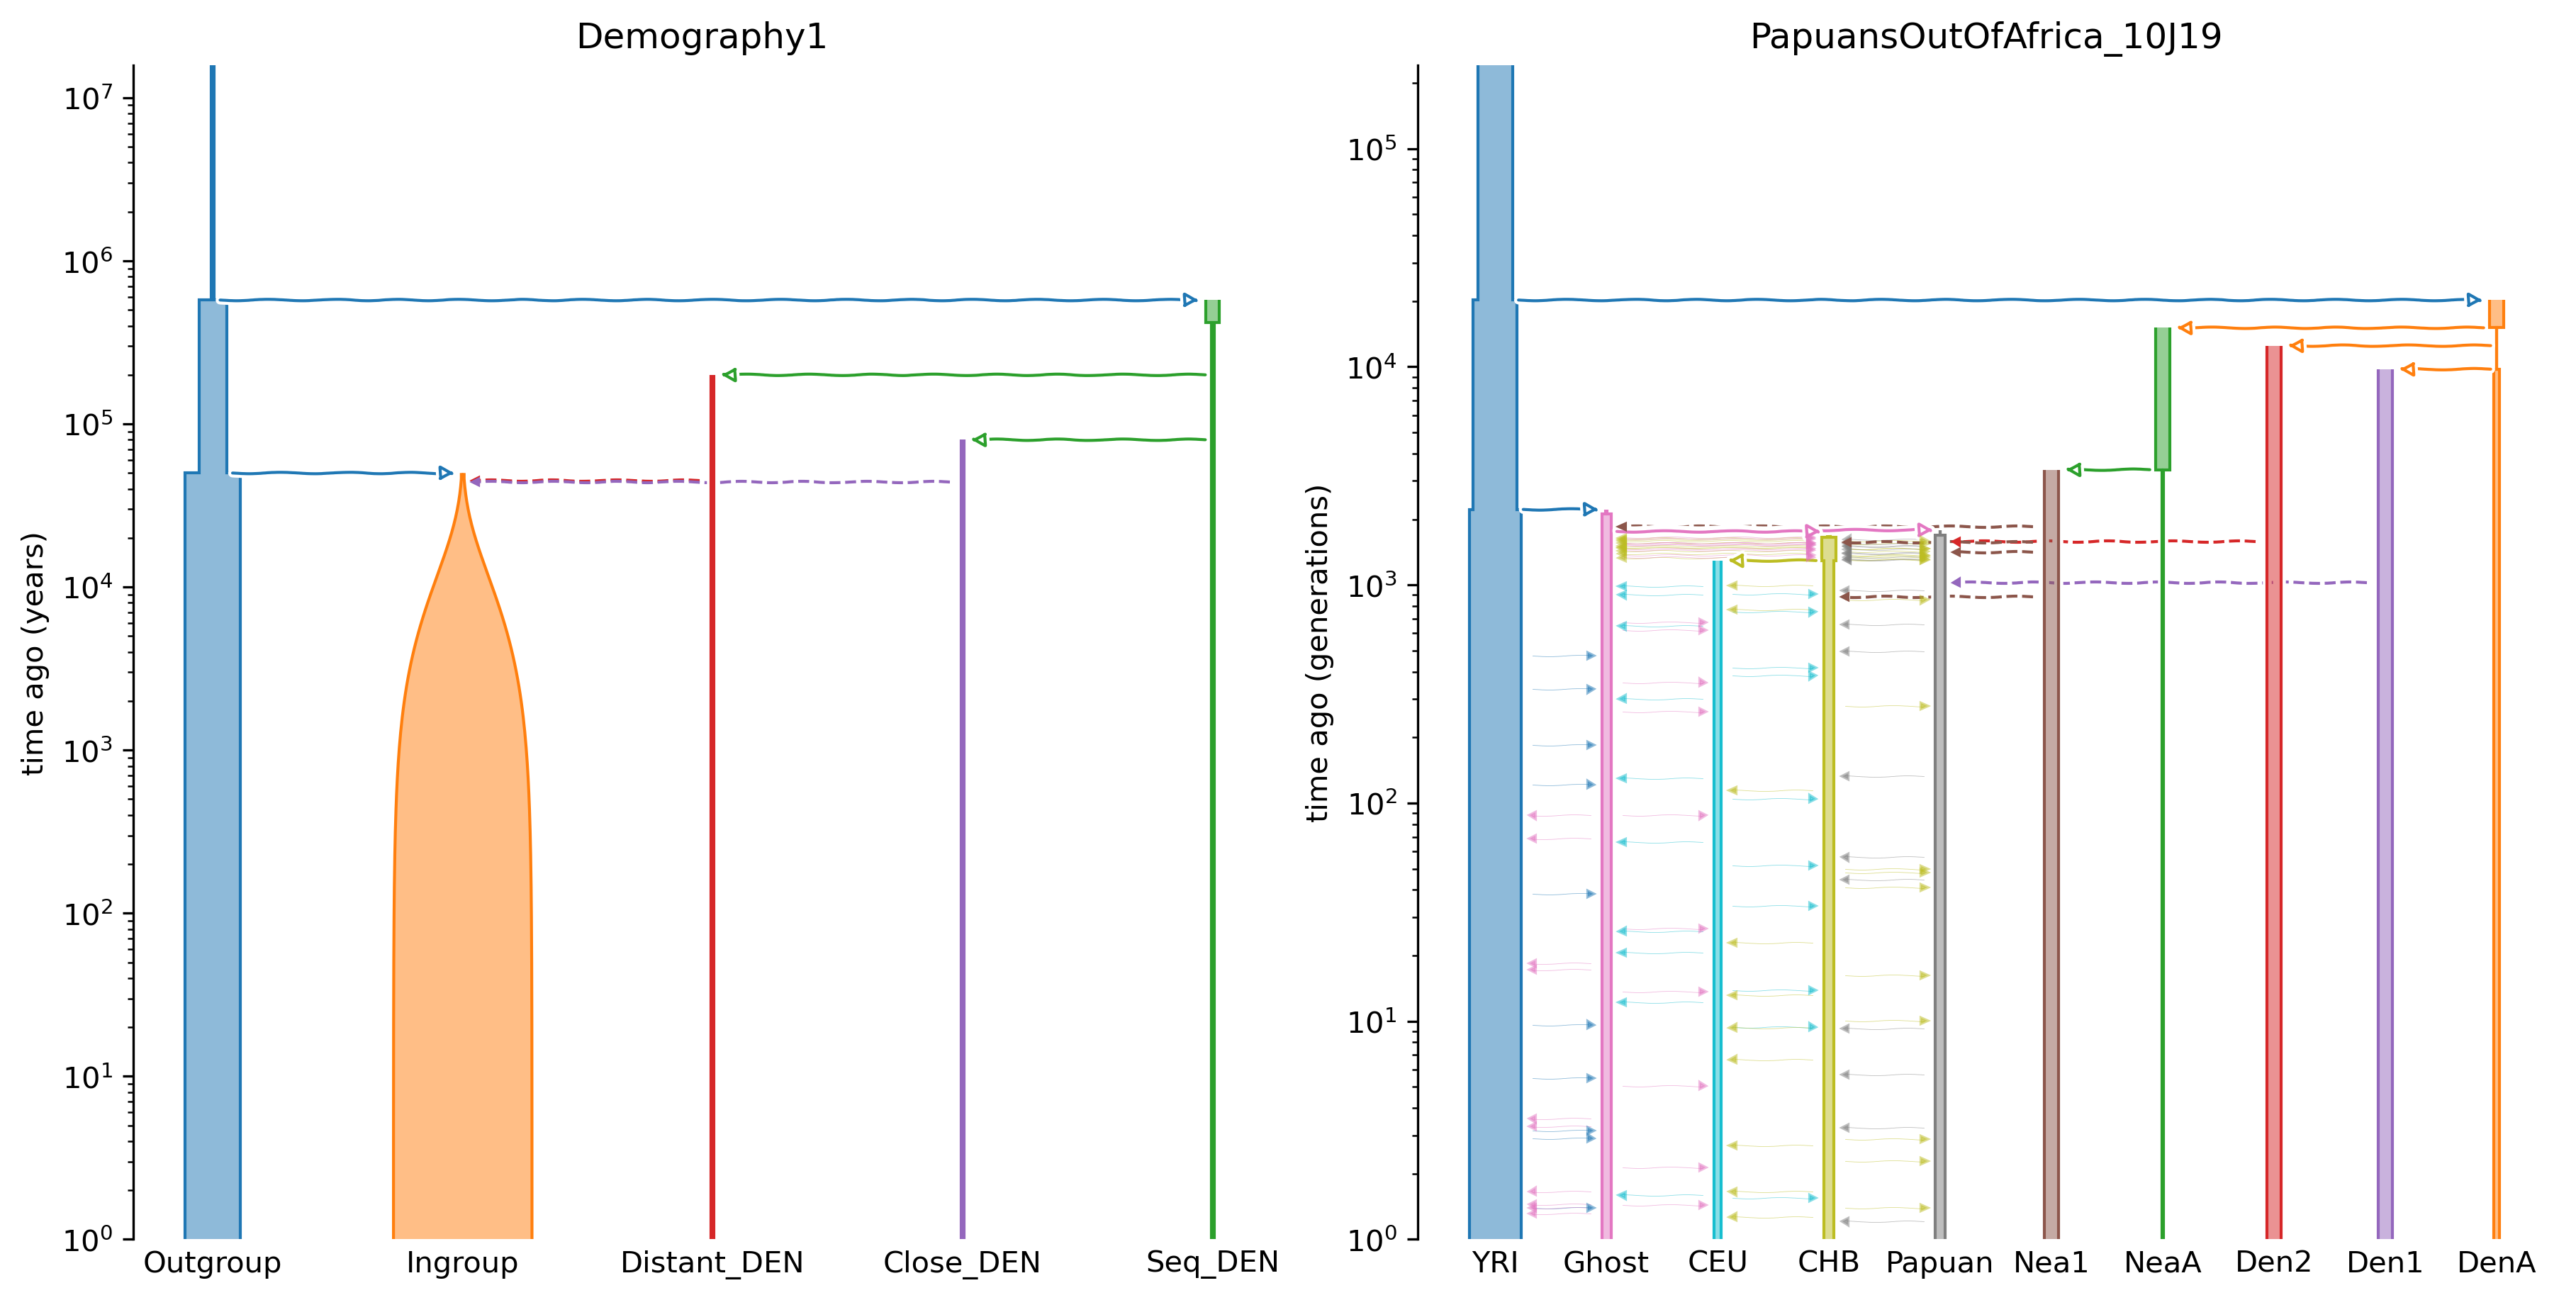

In [9]:
# Load the demes graphs.
Demography1_graph = demes.load("../Demography1.yaml")
PapuansOutOfAfrica_10J19_graph = demes.load("../PapuansOutOfAfrica_10J19.yaml")

# Try to make the plot pretty.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6),
    sharex=False,
    sharey=False,
    constrained_layout=True,
    dpi=300,
)
axes = axes.flatten()
Demography1_w = demesdraw.utils.separation_heuristic(Demography1_graph)
PapuansOutOfAfrica_10J19_w = demesdraw.utils.separation_heuristic(
    PapuansOutOfAfrica_10J19_graph
)
Demography1_positions1 = demesdraw.utils.minimal_crossing_positions(
    Demography1_graph, sep=Demography1_w, unique_interactions=False
)
PapuansOutOfAfrica_10J19_positions1 = demesdraw.utils.minimal_crossing_positions(
    PapuansOutOfAfrica_10J19_graph,
    sep=PapuansOutOfAfrica_10J19_w,
    unique_interactions=False,
)
Demography1_positions2 = demesdraw.utils.optimise_positions(
    Demography1_graph,
    positions=Demography1_positions1,
    sep=Demography1_w,
    unique_interactions=False,
)
PapuansOutOfAfrica_10J19_positions2 = demesdraw.utils.optimise_positions(
    PapuansOutOfAfrica_10J19_graph,
    positions=PapuansOutOfAfrica_10J19_positions1,
    sep=PapuansOutOfAfrica_10J19_w,
    unique_interactions=False,
)
demesdraw.tubes(
    Demography1_graph,
    positions=Demography1_positions2,
    log_time=True,
    ax=axes[0],
)
demesdraw.tubes(
    PapuansOutOfAfrica_10J19_graph,
    positions=PapuansOutOfAfrica_10J19_positions2,
    log_time=True,
    ax=axes[1],
)
axes[0].set_title("Demography1")
axes[1].set_title("PapuansOutOfAfrica_10J19")
plt.show()

Ok so Demography1 has two single pulse migration events, and PapuansOutOfAfrica_10J19 is a bit more complicated. My code only does one migration event at a time, and I am too lazy to change that at the moment, so I will need to inspect the demes graphs to get the relevant information.

In [10]:
# Define a function to extract the migration events from a demes graph.
def extract_demes_migration_events(graph):
    # Initialize a dictionary to store the results.
    migration_events = {
        "donor": [],
        "recipient": [],
        "mig_time": [],
        "type": [],
    }
    # Iterate through the migration events.
    for migration in graph.migrations:
        # Update the dictionary.
        migration_events["donor"].append(migration.source)
        migration_events["recipient"].append(migration.dest)
        migration_events["mig_time"].append(
            (
                migration.end_time / graph.generation_time,
                migration.start_time / graph.generation_time,
            )
            if graph.time_units == "years"
            else (migration.end_time, migration.start_time)
        )
        migration_events["type"].append("migration")
    # Iterate through the pulse events.
    for pulse in graph.pulses:
        # Iterate through the sources.
        for source in pulse.sources:
            # Update the dictionary.
            migration_events["donor"].append(source)
            migration_events["recipient"].append(pulse.dest)
            migration_events["mig_time"].append(
                pulse.time / graph.generation_time
                if graph.time_units == "years"
                else pulse.time
            )
            migration_events["type"].append("pulse")
    return pd.DataFrame(migration_events)

In [11]:
# Extract and display the migration events from the demes graphs as a sanity check.
events_dicc = {}
events_dicc["Demography1"] = extract_demes_migration_events(Demography1_graph)
events_dicc["PapuansOutOfAfrica_10J19"] = extract_demes_migration_events(
    PapuansOutOfAfrica_10J19_graph
)

for model, events_df in events_dicc.items():
    print(f"#***# {model} #***#")
    display(events_df)

#***# Demography1 #***#


,donor,recipient,mig_time,type
0,Distant_DEN,Ingroup,1551.724138,pulse
1,Close_DEN,Ingroup,1517.241379,pulse


#***# PapuansOutOfAfrica_10J19 #***#


,donor,recipient,mig_time,type
0,YRI,Ghost,"(0, 1659.0)",migration
1,Ghost,YRI,"(0, 1659.0)",migration
2,CHB,Papuan,"(1293.0, 1659.0)",migration
3,Papuan,CHB,"(1293.0, 1659.0)",migration
4,CHB,Papuan,"(0, 1293.0)",migration
5,Papuan,CHB,"(0, 1293.0)",migration
6,CHB,Ghost,"(1293.0, 1659.0)",migration
7,Ghost,CHB,"(1293.0, 1659.0)",migration
8,CEU,CHB,"(0, 1293.0)",migration
9,CHB,CEU,"(0, 1293.0)",migration


Ok so after some trial and error trying to figure out the most straightforward way to compare my segments to Skov's, I think I will need some convenience functions to make my life easier.

In [12]:
# Define a function to find the intersection of two sorted list of intervals.
def intersect_intervals(intervals_a, intervals_b):
    # Initialize a list and two pointers.
    overlap, idx_a, idx_b = [], 0, 0
    # Iterate through both lists.
    while idx_a < len(intervals_a) and idx_b < len(intervals_b):
        start = max(intervals_a[idx_a][0], intervals_b[idx_b][0])
        end = min(intervals_a[idx_a][1], intervals_b[idx_b][1])
        # Record the overlap if there is any.
        if end > start:
            overlap.append((start, end))
        # Advance the pointer of the list where the interval ends first.
        if intervals_a[idx_a][1] < intervals_b[idx_b][1]:
            idx_a += 1
        else:
            idx_b += 1
    return overlap


# Define a function to find the union of a list of intervals.
def union_intervals(intervals):
    # Initialize a list and iterate through the sorted intervals.
    merged = []
    for start, end in sorted(intervals):
        # If the current interval overlaps with the previous one, merge them.
        if merged and start <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], end))
        # Otherwise, add the current interval to the list.
        else:
            merged.append((start, end))
    return merged


# Define a function to subset a set of segments from Skov's output that belong to a specified demes event.
def subset_skov_event(skov_df, event):
    # Skov labels each segment by "donor>recipient" migration event.
    is_label = skov_df.admix_event == f"{event.donor}>{event.recipient}"
    # As of commit 104fa43 (line 73), Skov writes the "admixtime" rounded to one decimal place.
    if event.type == "pulse":
        is_time = skov_df.admixtime == round(event.mig_time, 1)
    else:
        is_time = (skov_df.admixtime >= round(event.mig_time[0], 1)) & (
            skov_df.admixtime <= round(event.mig_time[1], 1)
        )
    return skov_df[is_label & is_time]

Now time to compare!

In [13]:
# Initialize a dictionary and a list to store the results.
dave_dicc = {}
comparison_rows = []
# Initialize a dictionary of recipient populations that Skov queries.
recipient_pops = {
    "Demography1": ["Ingroup"],
    "PapuansOutOfAfrica_10J19": ["Papuan", "CHB", "CEU", "YRI"],
}

# Compare both models.
for model, events_df in events_dicc.items():
    # Load Skov's segments.
    skov_df = pd.read_csv(f"{model}_segment_test.txt", sep="\t")

    # For every replicate iteration.
    for iteration in range(10):
        # Subset Skov's segments to this iteration.
        iteration_skov_df = skov_df[skov_df.iteration == iteration]
        # Load the tree-sequence.
        ts = tskit.load(f"{model}.ts.seed_1234.iteration_{iteration}.trees")
        # Initialize a population name to ID map.
        name2id = {pop.metadata["name"]: pop.id for pop in ts.populations()}
        # Extract the populations and haplotypes Skov queries.
        query_pops = [name2id[pop] for pop in recipient_pops[model]]
        query_haps = set()
        for pop in query_pops:
            query_haps.update(ts.samples(pop))

        # Iterate through the migration events.
        for event_idx, event in events_df.iterrows():
            # Call migrating segments using my method.
            tree_df = find_migrating_trees(
                ts=ts,
                sample_pop_list=query_pops,
                donor_pop=name2id[event.donor],
                recipient_pop=name2id[event.recipient],
                mig_time=event.mig_time,
            )
            seg_df = extract_migrating_segments(tree_df)
            # Update my results.
            dave_dicc[model, iteration, event_idx] = {
                "tree_df": tree_df,
                "seg_df": seg_df,
            }
            # Subset Skov's segments that match this event.
            event_skov_df = subset_skov_event(iteration_skov_df, event)

            # Iterate through the query haplotypes.
            for hap in query_haps:
                # Dave's segment intervals for this haplotype.
                dave_intervals = [
                    (int(s), int(e))
                    for s, e in seg_df.loc[
                        seg_df.hap_id == hap, ["start", "end"]
                    ].values
                ]
                # Skov's segment intervals for this haplotype.
                skov_intervals = union_intervals(
                    [
                        (int(s), int(e))
                        for s, e in event_skov_df.loc[
                            event_skov_df.haplotype == hap, ["start", "end"]
                        ].values
                    ]
                )
                # Compute the total amount of overlap.
                overlap_bp = sum(
                    e - s
                    for s, e in intersect_intervals(dave_intervals, skov_intervals)
                )
                # Update the comparison rows.
                comparison_rows.append(
                    {
                        "model": model,
                        "iteration": iteration,
                        "event": f"{event.donor}>{event.recipient}",
                        "event_type": event.type,
                        "event_idx": event_idx,
                        "mig_time": event.mig_time,
                        "hap_id": hap,
                        "n_dave": len(dave_intervals),
                        "n_skov": len(skov_intervals),
                        "bp_dave": sum(e - s for s, e in dave_intervals),
                        "bp_skov": sum(e - s for s, e in skov_intervals),
                        "bp_overlap": overlap_bp,
                        "identical": dave_intervals == skov_intervals,
                    }
                )

# Convert the list of rows to a dataframe.
comparison_df = pd.DataFrame(comparison_rows)
comparison_df["bp_only_dave"] = comparison_df.bp_dave - comparison_df.bp_overlap
comparison_df["bp_only_skov"] = comparison_df.bp_skov - comparison_df.bp_overlap

# Summarize the comparisons.
summary_df = (
    comparison_df.groupby(
        ["model", "event", "event_idx", "event_type", "mig_time"], sort=False
    )
    .agg(
        n_hap_iters=("identical", "size"),
        n_identical=("identical", "sum"),
        n_segs_dave=("n_dave", "sum"),
        n_segs_skov=("n_skov", "sum"),
        bp_overlap=("bp_overlap", "sum"),
        bp_only_dave=("bp_only_dave", "sum"),
        bp_only_skov=("bp_only_skov", "sum"),
    )
    .reset_index()
)
summary_df

,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov
0,Demography1,Distant_DEN>Ingroup,0,pulse,1551.724138,20,18,603,603,40089329,0,3646
1,Demography1,Close_DEN>Ingroup,1,pulse,1517.241379,20,18,221,221,11574621,0,1303
2,PapuansOutOfAfrica_10J19,YRI>Ghost,0,migration,"(0, 1659.0)",80,60,286,286,19146080,0,4752
3,PapuansOutOfAfrica_10J19,Ghost>YRI,1,migration,"(0, 1659.0)",80,61,494,494,49857446,0,14400
4,PapuansOutOfAfrica_10J19,CHB>Papuan,2,migration,"(1293.0, 1659.0)",80,43,801,801,47174721,0,24229
5,PapuansOutOfAfrica_10J19,Papuan>CHB,3,migration,"(1293.0, 1659.0)",80,21,1132,1132,65203116,0,34771
6,PapuansOutOfAfrica_10J19,CHB>Papuan,4,migration,"(0, 1293.0)",80,69,113,113,9868099,0,3636
7,PapuansOutOfAfrica_10J19,Papuan>CHB,5,migration,"(0, 1293.0)",80,72,116,116,18303218,0,4493
8,PapuansOutOfAfrica_10J19,CHB>Ghost,6,migration,"(1293.0, 1659.0)",80,45,320,320,16480475,0,7923
9,PapuansOutOfAfrica_10J19,Ghost>CHB,7,migration,"(1293.0, 1659.0)",80,31,911,911,47512153,0,24666


So there are indeed some differences, let's check the number of segments and the length of the segments.

In [14]:
# Determine when either method calls more segments than the other.
is_dave_more_segs = summary_df.n_segs_dave > summary_df.n_segs_skov
is_skov_more_segs = summary_df.n_segs_skov > summary_df.n_segs_dave

print("#***# Dave calls more segments than Skov #***#")
display(summary_df[is_dave_more_segs])

print("#***# Skov calls more segments than Dave #***#")
display(summary_df[is_skov_more_segs])

#***# Dave calls more segments than Skov #***#


,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov


#***# Skov calls more segments than Dave #***#


,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov


In [15]:
# Sanity check.
(comparison_df.n_skov.values == comparison_df.n_dave.values).sum(), comparison_df.shape[
    0
]

(np.int64(1480), 1480)

In [16]:
# Determine where either method calls more length than the other.
is_dave_more_bp = summary_df.bp_only_dave > summary_df.bp_only_skov
is_skov_more_bp = summary_df.bp_only_skov > summary_df.bp_only_dave

print("#***# Dave calls more length than Skov #***#")
display(summary_df[is_dave_more_bp])

print("#***# Skov calls more length than Dave #***#")
display(summary_df[is_skov_more_bp])

#***# Dave calls more length than Skov #***#


,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov


#***# Skov calls more length than Dave #***#


,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov
0,Demography1,Distant_DEN>Ingroup,0,pulse,1551.724138,20,18,603,603,40089329,0,3646
1,Demography1,Close_DEN>Ingroup,1,pulse,1517.241379,20,18,221,221,11574621,0,1303
2,PapuansOutOfAfrica_10J19,YRI>Ghost,0,migration,"(0, 1659.0)",80,60,286,286,19146080,0,4752
3,PapuansOutOfAfrica_10J19,Ghost>YRI,1,migration,"(0, 1659.0)",80,61,494,494,49857446,0,14400
4,PapuansOutOfAfrica_10J19,CHB>Papuan,2,migration,"(1293.0, 1659.0)",80,43,801,801,47174721,0,24229
5,PapuansOutOfAfrica_10J19,Papuan>CHB,3,migration,"(1293.0, 1659.0)",80,21,1132,1132,65203116,0,34771
6,PapuansOutOfAfrica_10J19,CHB>Papuan,4,migration,"(0, 1293.0)",80,69,113,113,9868099,0,3636
7,PapuansOutOfAfrica_10J19,Papuan>CHB,5,migration,"(0, 1293.0)",80,72,116,116,18303218,0,4493
8,PapuansOutOfAfrica_10J19,CHB>Ghost,6,migration,"(1293.0, 1659.0)",80,45,320,320,16480475,0,7923
9,PapuansOutOfAfrica_10J19,Ghost>CHB,7,migration,"(1293.0, 1659.0)",80,31,911,911,47512153,0,24666


In [17]:
# Determine when the two methods are not identical.
not_identical_df = comparison_df[comparison_df.identical == False]
not_identical_df

,model,iteration,event,event_type,event_idx,mig_time,hap_id,n_dave,n_skov,bp_dave,bp_skov,bp_overlap,identical,bp_only_dave,bp_only_skov
5,Demography1,1,Distant_DEN>Ingroup,pulse,0,1551.724138,1,33,33,2414697,2415190,2414697,False,0,493
7,Demography1,1,Close_DEN>Ingroup,pulse,1,1517.241379,1,14,14,668111,668670,668111,False,0,559
25,Demography1,6,Distant_DEN>Ingroup,pulse,0,1551.724138,1,39,39,2811552,2814705,2811552,False,0,3153
27,Demography1,6,Close_DEN>Ingroup,pulse,1,1517.241379,1,15,15,859129,859873,859129,False,0,744
44,PapuansOutOfAfrica_10J19,0,YRI>Ghost,migration,0,"(0, 1659.0)",4,7,7,289592,289593,289592,False,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1422,PapuansOutOfAfrica_10J19,9,CEU>Ghost,migration,10,"(0, 1293.0)",10,6,6,1067061,1067882,1067061,False,0,821
1428,PapuansOutOfAfrica_10J19,9,Ghost>CEU,migration,11,"(0, 1293.0)",4,27,27,3801555,3802346,3801555,False,0,791
1429,PapuansOutOfAfrica_10J19,9,Ghost>CEU,migration,11,"(0, 1293.0)",5,23,23,4249227,4250624,4249227,False,0,1397
1435,PapuansOutOfAfrica_10J19,9,Nea1>Ghost,pulse,12,1853.0,3,10,10,305024,305214,305024,False,0,190


In [18]:
# For each demographic model, iteration, and migration event, determine the number of times the migrating segment partially overlaps the marginal tree per (haplotype, marginal tree) pair.
for key in dave_dicc:
    tree_df = dave_dicc[key]["tree_df"]
    # Determine what marginal trees are partially overlapped by a migrating segment for each haplotype.
    min_o_perct = tree_df.groupby(["hap_id", "t_idx"]).o_perct.min()
    n_lt_1 = (min_o_perct < 1).sum()
    # Determine the total number of (haplotype, marginal tree) pairs and print a summary.
    n_pairs = len(min_o_perct)
    model, iteration, event_idx = key
    event = events_dicc[model].iloc[event_idx]
    print(
        f"#***# model: {model}, iteration: {iteration}, event: {event.donor}>{event.recipient} #***#"
    )
    print(f"total number of (haplotype, marginal tree) pairs w/ any overlap: {n_pairs}")
    print(
        f"total number of (haplotype, marginal tree) pairs w/ < 100% overlap: {n_lt_1}"
    )
    print(
        f"percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: {n_lt_1 / n_pairs if n_pairs > 0 else np.nan}"
    )

#***# model: Demography1, iteration: 0, event: Distant_DEN>Ingroup #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 2181
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 3
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.001375515818431912
#***# model: Demography1, iteration: 0, event: Close_DEN>Ingroup #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 316
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 0
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.0
#***# model: Demography1, iteration: 1, event: Distant_DEN>Ingroup #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 3470
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 18
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.005187319884726225
#***# model: Demography1, iteration: 1, event: Close_DEN>Ingroup #***#
total number of (haplotype, marginal tree) pairs

#***# model: PapuansOutOfAfrica_10J19, iteration: 2, event: CHB>Papuan #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 32009
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 24
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.000749789121809491
#***# model: PapuansOutOfAfrica_10J19, iteration: 2, event: Papuan>CHB #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 41702
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 20
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.00047959330487746393
#***# model: PapuansOutOfAfrica_10J19, iteration: 2, event: CHB>Papuan #***#
total number of (haplotype, marginal tree) pairs w/ any overlap: 6516
total number of (haplotype, marginal tree) pairs w/ < 100% overlap: 1
percentage of (haplotype, marginal tree) pairs w/ < 100% overlap: 0.0001534683855125844
#***# model: PapuansOutOfAfrica_10J19, iteration: 2, event: Papuan>CHB #***#
tota

So the nice thing is Skov and I always infer the same number of segments, after accounting for how Skov stratifies his segments by time, and we only disagree on the length of the segments. Based on commit `104fa43`, my hypothesis is that `introgressed_seg[l, admixinfo].append([tree_left, tree_right])` (on line 81) is the culprit since it seems like Skov is calling the whole marginal tree a segment even when the migrating segment does not overlap the entire tree. The cells above shows that these types of segments are rare, but they do exist. I investigate, whether my hunch is correct below.

In [19]:
# Define a function to find the partial overlap gaps between the migrating segments and the marginal trees.
def find_partial_overlap_gaps(tree_df):
    """Find the uncovered gaps of every migrating segment wrt the the marginal trees.

    Args:
        tree_df (pandas.DataFrame): Output of find_migrating_trees.

    Returns:
        pandas.DataFrame: One row per uncovered gap with the following columns:
            - hap_id: The node ID of the haplotype.
            - t_idx: The index of the marginal tree.
            - t_l: The left position of the marginal tree.
            - t_r: The right position of the marginal tree.
            - t_span: The span of the marginal tree.
            - gap_start: The left position of the uncovered gap.
            - gap_end: The right position of the uncovered gap.
            - gap_len: The length of the uncovered gap.
            - location: Whether the gap is at the left, right, or interior of the marginal tree.
    """
    # Initialize a dictionary to store the results.
    gap_dicc = {
        "hap_id": [],
        "t_idx": [],
        "t_l": [],
        "t_r": [],
        "t_span": [],
        "gap_start": [],
        "gap_end": [],
        "gap_len": [],
        "location": [],
    }
    # Determine what marginal trees are partially overlapped by a migrating segment.
    is_partial = tree_df.groupby(["hap_id", "t_idx"]).o_perct.transform("min") < 1

    # Iterate over every (haplotype, marginal tree) pair with at least one partially overlapping migrating segment.
    for (hap_id, t_idx), group_df in tree_df[is_partial].groupby(["hap_id", "t_idx"]):
        # Extract the marginal tree's coordinates.
        t_l, t_r = group_df.t_l.iloc[0], group_df.t_r.iloc[0]
        # Clip the overlaps and find the union between them.
        covered_intervals = union_intervals(
            zip(
                np.maximum(group_df.t_l, group_df.m_l),
                np.minimum(group_df.t_r, group_df.m_r),
            )
        )
        # Initialize a pointer to find the uncovered gaps.
        c_gap = t_l

        # Iterate over the covered intervals to find the uncovered gaps.
        # Note that the last appended interval accounts for the gap being between the last covered interval and the right edge of the marginal tree.
        for covered_start, covered_end in covered_intervals + [(t_r, t_r)]:
            # If the covered interval's start is after the current gap position, record the uncovered gap.
            if covered_start > c_gap:
                gap_dicc["hap_id"].append(hap_id)
                gap_dicc["t_idx"].append(t_idx)
                gap_dicc["t_l"].append(t_l)
                gap_dicc["t_r"].append(t_r)
                gap_dicc["t_span"].append(t_r - t_l)
                gap_dicc["gap_start"].append(c_gap)
                gap_dicc["gap_end"].append(covered_start)
                gap_dicc["gap_len"].append(covered_start - c_gap)
                # Determine the location of the uncovered gap.
                if c_gap == t_l:
                    gap_dicc["location"].append("left")
                elif covered_start == t_r:
                    gap_dicc["location"].append("right")
                else:
                    gap_dicc["location"].append("interior")
            # Start the next gap after the covered interval.
            c_gap = max(c_gap, covered_end)
    return pd.DataFrame(gap_dicc)

In [20]:
# Initialize a list to store the results.
uncovered_gap_dfs = []

# Iterate through every model, iteration, and migration event.
for key in dave_dicc:
    # Extract the tree and segment dataframes then unpack the key.
    tree_df, seg_df = dave_dicc[key]["tree_df"], dave_dicc[key]["seg_df"]
    model, iteration, event_idx = key
    # Skip if the tree is never covered by migrating segments.
    if tree_df.empty:
        continue
    # Find the uncovered gaps, if any.
    gap_df = find_partial_overlap_gaps(tree_df)
    # Skip if there are no uncovered gaps.
    if gap_df.empty:
        continue
    # Extract the migration event.
    event = events_dicc[model].iloc[event_idx]
    # Annotate the metadata.
    gap_df.insert(0, "model", model)
    gap_df.insert(1, "iteration", iteration)
    gap_df.insert(2, "event", f"{event.donor}>{event.recipient}")
    gap_df.insert(3, "event_type", event.type)
    gap_df.insert(4, "event_idx", event_idx)
    # Initialize lists for the uncovered gap segment bookkeeping.
    left_seg_idxs, right_seg_idxs, other_bp, other_events = [], [], [], []

    # Iterate through the uncovered gaps.
    for gap in gap_df.itertuples():
        # Extract this haplotype's segments.
        hap_seg_df = seg_df[seg_df.hap_id == gap.hap_id]
        # Find the segments that end at the gap's start (i.e., the gap extends the segment's end to the right).
        is_left_seg = hap_seg_df.end == gap.gap_start
        # Find the segments that start at the gap's end (i.e., the gap extends the segment's start to the left).
        is_right_seg = hap_seg_df.start == gap.gap_end
        # Record the index of the segments if it exists, otherwise record -1.
        left_seg_idxs.append(
            hap_seg_df.index[is_left_seg][0] if is_left_seg.any() else -1
        )
        right_seg_idxs.append(
            hap_seg_df.index[is_right_seg][0] if is_right_seg.any() else -1
        )
        # Initialize lists to track if the gap is recorded by a different migration event.
        diff_intervals, diff_events = [], []

        # Iterate through the other migration events for the same model and iteration.
        for other_idx, other_event in events_dicc[model].iterrows():
            # Skip the current migration event.
            if other_idx == event_idx:
                continue
            # Extract the other event's segments that overlap the gap.
            other_seg_df = dave_dicc[model, iteration, other_idx]["seg_df"]
            other_intervals = intersect_intervals(
                [(gap.gap_start, gap.gap_end)],
                [
                    (s, e)
                    for s, e in other_seg_df.loc[
                        other_seg_df.hap_id == gap.hap_id, ["start", "end"]
                    ].values
                ],
            )
            # Record the other migration event and its intervals if it covers any of the gap.
            if other_intervals:
                diff_intervals += other_intervals
                diff_events.append(f"{other_event.donor}>{other_event.recipient}")

        # Merge the other events' intervals to account for the gap being covered by possibly multiple other migration events.
        other_bp.append(sum(e - s for s, e in union_intervals(diff_intervals)))
        other_events.append(",".join(diff_events))

    # Append the information to the uncovered gap dataframe.
    gap_df["left_seg_idx"] = left_seg_idxs
    gap_df["right_seg_idx"] = right_seg_idxs
    gap_df["seg_idx"] = gap_df[["left_seg_idx", "right_seg_idx"]].max(axis=1)
    gap_df["bp_in_other_events"] = other_bp
    gap_df["other_events"] = other_events
    # Update the results.
    uncovered_gap_dfs.append(gap_df)

# Concatenate the results.
uncovered_gap_df = pd.concat(uncovered_gap_dfs, ignore_index=True)
uncovered_gap_df

,model,iteration,event,event_type,event_idx,hap_id,t_idx,t_l,t_r,t_span,gap_start,gap_end,gap_len,location,left_seg_idx,right_seg_idx,seg_idx,bp_in_other_events,other_events
0,Demography1,1,Distant_DEN>Ingroup,pulse,0,1,1977,2819841.0,2820893.0,1052.0,2819841.0,2820334.0,493.0,left,-1,48,48,493.0,Close_DEN>Ingroup
1,Demography1,1,Close_DEN>Ingroup,pulse,1,1,1977,2819841.0,2820893.0,1052.0,2820334.0,2820893.0,559.0,right,16,-1,16,559.0,Distant_DEN>Ingroup
2,Demography1,6,Distant_DEN>Ingroup,pulse,0,1,4110,5839579.0,5843476.0,3897.0,5839579.0,5842732.0,3153.0,left,-1,56,56,3153.0,Close_DEN>Ingroup
3,Demography1,6,Close_DEN>Ingroup,pulse,1,1,4110,5839579.0,5843476.0,3897.0,5842732.0,5843476.0,744.0,right,14,-1,14,744.0,Distant_DEN>Ingroup
4,PapuansOutOfAfrica_10J19,0,YRI>Ghost,migration,0,4,4407,857280.0,857336.0,56.0,857335.0,857336.0,1.0,right,2,-1,2,0.0,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
752,PapuansOutOfAfrica_10J19,9,Ghost>CEU,migration,11,5,24408,4623671.0,4624019.0,348.0,4623671.0,4623696.0,25.0,left,-1,38,38,25.0,Papuan>CHB
753,PapuansOutOfAfrica_10J19,9,Ghost>CEU,migration,11,5,25367,4800770.0,4800953.0,183.0,4800898.0,4800953.0,55.0,right,38,-1,38,0.0,
754,PapuansOutOfAfrica_10J19,9,Ghost>CEU,migration,11,5,31159,5914172.0,5914644.0,472.0,5914172.0,5914636.0,464.0,left,-1,45,45,0.0,
755,PapuansOutOfAfrica_10J19,9,Nea1>Ghost,pulse,12,3,11052,2058508.0,2058746.0,238.0,2058556.0,2058746.0,190.0,right,18,-1,18,190.0,Nea1>CHB


In [21]:
# Initialize the grouping columns.
event_cols = ["model", "event", "event_type", "event_idx"]

# Summarize the uncovered gap results.
gap_summary_df = (
    uncovered_gap_df.groupby(event_cols, sort=False)
    .agg(
        n_gap_trees=("t_idx", "size"),
        n_left=("location", lambda x: (x == "left").sum()),
        n_right=("location", lambda x: (x == "right").sum()),
        n_interior=("location", lambda x: (x == "interior").sum()),
        bp_gap=("gap_len", "sum"),
        n_in_other_events=("bp_in_other_events", lambda x: (x > 0).sum()),
        bp_in_other_events=("bp_in_other_events", "sum"),
    )
    .reset_index()
)

# Determine the unique segments with any uncovered gaps, since a segment may have multiple gaps.
segs_with_gap_df = (
    uncovered_gap_df.drop_duplicates(
        ["model", "iteration", "event_idx", "hap_id", "seg_idx"]
    )
    .groupby(event_cols, sort=False)
    .size()
    .reset_index(name="n_gap_segs")
)

# Merge the two summary dataframes.
gap_summary_df = (
    summary_df[event_cols]
    .merge(segs_with_gap_df, how="left", on=event_cols)
    .merge(gap_summary_df, how="left", on=event_cols)
    .fillna(0)
)
# Append the total number of segments and the total length per event.
gap_summary_df["n_segs"] = summary_df.n_segs_dave.values
gap_summary_df["bp_segs"] = (
    summary_df.bp_overlap.values + summary_df.bp_only_dave.values
)
# Compute the percentage of segments with uncovered gaps.
gap_summary_df["perct_segs_w_gaps"] = gap_summary_df.n_gap_segs / gap_summary_df.n_segs
gap_summary_df["perct_bp_w_gaps"] = gap_summary_df.bp_gap / gap_summary_df.bp_segs
gap_summary_df

,model,event,event_type,event_idx,n_gap_segs,n_gap_trees,n_left,n_right,n_interior,bp_gap,n_in_other_events,bp_in_other_events,n_segs,bp_segs,perct_segs_w_gaps,perct_bp_w_gaps
0,Demography1,Distant_DEN>Ingroup,pulse,0,2.0,2.0,2.0,0.0,0.0,3646.0,2.0,3646.0,603,40089329,0.003317,0.000091
1,Demography1,Close_DEN>Ingroup,pulse,1,2.0,2.0,0.0,2.0,0.0,1303.0,2.0,1303.0,221,11574621,0.009050,0.000113
2,PapuansOutOfAfrica_10J19,YRI>Ghost,migration,0,28.0,28.0,11.0,17.0,0.0,4752.0,18.0,3449.0,286,19146080,0.097902,0.000248
3,PapuansOutOfAfrica_10J19,Ghost>YRI,migration,1,58.0,63.0,24.0,39.0,0.0,14400.0,2.0,331.0,494,49857446,0.117409,0.000289
4,PapuansOutOfAfrica_10J19,CHB>Papuan,migration,2,106.0,113.0,51.0,62.0,0.0,24229.0,15.0,1893.0,801,47174721,0.132335,0.000514
5,PapuansOutOfAfrica_10J19,Papuan>CHB,migration,3,161.0,162.0,89.0,73.0,0.0,34771.0,46.0,9399.0,1132,65203116,0.142226,0.000533
6,PapuansOutOfAfrica_10J19,CHB>Papuan,migration,4,13.0,15.0,8.0,7.0,0.0,3636.0,2.0,222.0,113,9868099,0.115044,0.000368
7,PapuansOutOfAfrica_10J19,Papuan>CHB,migration,5,14.0,15.0,9.0,6.0,0.0,4493.0,5.0,1158.0,116,18303218,0.120690,0.000245
8,PapuansOutOfAfrica_10J19,CHB>Ghost,migration,6,57.0,59.0,29.0,30.0,0.0,7923.0,38.0,5093.0,320,16480475,0.178125,0.000481
9,PapuansOutOfAfrica_10J19,Ghost>CHB,migration,7,130.0,137.0,65.0,72.0,0.0,24666.0,42.0,7898.0,911,47512153,0.142700,0.000519


In [22]:
# Check that the uncovered gaps account for the excess segment length Skov calls.
check_df = gap_summary_df[["model", "event_idx", "bp_gap"]].merge(
    summary_df[["model", "event_idx", "bp_only_skov"]], on=["model", "event_idx"]
)
check_df["bp_gap_equals_bp_only_skov"] = check_df.bp_gap == check_df.bp_only_skov
print(
    f"Skov's excess bp == uncovered gaps for every event?: {(check_df.bp_gap == check_df.bp_only_skov).all()}"
)

# Check that every gap is next to one of my segments.
is_next_to_seg = (uncovered_gap_df.left_seg_idx >= 0) | (
    uncovered_gap_df.right_seg_idx >= 0
)
print(f"Is every gap next to one of my segments?: {(is_next_to_seg).all()}")

# Check the number of gaps that would merge two of my segments.
is_merging_segs = (uncovered_gap_df.left_seg_idx >= 0) & (
    uncovered_gap_df.right_seg_idx >= 0
)
print(f"Number of gaps that would merge two of my segments: {is_merging_segs.sum()}")
check_df

Skov's excess bp == uncovered gaps for every event?: True
Is every gap next to one of my segments?: True
Number of gaps that would merge two of my segments: 0


,model,event_idx,bp_gap,bp_only_skov,bp_gap_equals_bp_only_skov
0,Demography1,0,3646.0,3646,True
1,Demography1,1,1303.0,1303,True
2,PapuansOutOfAfrica_10J19,0,4752.0,4752,True
3,PapuansOutOfAfrica_10J19,1,14400.0,14400,True
4,PapuansOutOfAfrica_10J19,2,24229.0,24229,True
5,PapuansOutOfAfrica_10J19,3,34771.0,34771,True
6,PapuansOutOfAfrica_10J19,4,3636.0,3636,True
7,PapuansOutOfAfrica_10J19,5,4493.0,4493,True
8,PapuansOutOfAfrica_10J19,6,7923.0,7923,True
9,PapuansOutOfAfrica_10J19,7,24666.0,24666,True


A: So given that the uncovered gaps between the migrating segments and the marginal trees account exactly for the excess segment length Skov calls, these uncovered gaps are always adjacent to one of my segments, and that Skov and I call the exact same number of segments suggests that `introgressed_seg[l, admixinfo].append([tree_left, tree_right])` (on line 81 in commit `104fa43`) is the culprit for the discrepancy. I believe the fix is to record the interval that the migrating segment overlaps with the marginal tree, i.e., `introgressed_seg[l, admixinfo].append([max(tree_left, int(mr.left)), min(tree_right, int(mr.right))])` and I validate this claim below by copying and pasting the previous comparison cells after running the modified `Keeptrack_of_introgressed.py` script.

In [23]:
# Initialize a dictionary and a list to store the results.
dave_dicc = {}
comparison_rows = []
# Initialize a dictionary of recipient populations that Skov queries.
recipient_pops = {
    "Demography1": ["Ingroup"],
    "PapuansOutOfAfrica_10J19": ["Papuan", "CHB", "CEU", "YRI"],
}

# Compare both models.
for model, events_df in events_dicc.items():
    # Load Skov's segments.
    skov_df = pd.read_csv(f"{model}_segment_fixed.txt", sep="\t")

    # For every replicate iteration.
    for iteration in range(10):
        # Subset Skov's segments to this iteration.
        iteration_skov_df = skov_df[skov_df.iteration == iteration]
        # Load the tree-sequence.
        ts = tskit.load(f"{model}.ts.seed_1234.iteration_{iteration}.trees")
        # Initialize a population name to ID map.
        name2id = {pop.metadata["name"]: pop.id for pop in ts.populations()}
        # Extract the populations and haplotypes Skov queries.
        query_pops = [name2id[pop] for pop in recipient_pops[model]]
        query_haps = set()
        for pop in query_pops:
            query_haps.update(ts.samples(pop))

        # Iterate through the migration events.
        for event_idx, event in events_df.iterrows():
            # Call migrating segments using my method.
            tree_df = find_migrating_trees(
                ts=ts,
                sample_pop_list=query_pops,
                donor_pop=name2id[event.donor],
                recipient_pop=name2id[event.recipient],
                mig_time=event.mig_time,
            )
            seg_df = extract_migrating_segments(tree_df)
            # Update my results.
            dave_dicc[model, iteration, event_idx] = {
                "tree_df": tree_df,
                "seg_df": seg_df,
            }
            # Subset Skov's segments that match this event.
            event_skov_df = subset_skov_event(iteration_skov_df, event)

            # Iterate through the query haplotypes.
            for hap in query_haps:
                # Dave's segment intervals for this haplotype.
                dave_intervals = [
                    (int(s), int(e))
                    for s, e in seg_df.loc[
                        seg_df.hap_id == hap, ["start", "end"]
                    ].values
                ]
                # Skov's segment intervals for this haplotype.
                skov_intervals = union_intervals(
                    [
                        (int(s), int(e))
                        for s, e in event_skov_df.loc[
                            event_skov_df.haplotype == hap, ["start", "end"]
                        ].values
                    ]
                )
                # Compute the total amount of overlap.
                overlap_bp = sum(
                    e - s
                    for s, e in intersect_intervals(dave_intervals, skov_intervals)
                )
                # Update the comparison rows.
                comparison_rows.append(
                    {
                        "model": model,
                        "iteration": iteration,
                        "event": f"{event.donor}>{event.recipient}",
                        "event_type": event.type,
                        "event_idx": event_idx,
                        "mig_time": event.mig_time,
                        "hap_id": hap,
                        "n_dave": len(dave_intervals),
                        "n_skov": len(skov_intervals),
                        "bp_dave": sum(e - s for s, e in dave_intervals),
                        "bp_skov": sum(e - s for s, e in skov_intervals),
                        "bp_overlap": overlap_bp,
                        "identical": dave_intervals == skov_intervals,
                    }
                )

# Convert the list of rows to a dataframe.
comparison_df = pd.DataFrame(comparison_rows)
comparison_df["bp_only_dave"] = comparison_df.bp_dave - comparison_df.bp_overlap
comparison_df["bp_only_skov"] = comparison_df.bp_skov - comparison_df.bp_overlap

# Summarize the comparisons.
summary_df = (
    comparison_df.groupby(
        ["model", "event", "event_idx", "event_type", "mig_time"], sort=False
    )
    .agg(
        n_hap_iters=("identical", "size"),
        n_identical=("identical", "sum"),
        n_segs_dave=("n_dave", "sum"),
        n_segs_skov=("n_skov", "sum"),
        bp_overlap=("bp_overlap", "sum"),
        bp_only_dave=("bp_only_dave", "sum"),
        bp_only_skov=("bp_only_skov", "sum"),
    )
    .reset_index()
)
summary_df

,model,event,event_idx,event_type,mig_time,n_hap_iters,n_identical,n_segs_dave,n_segs_skov,bp_overlap,bp_only_dave,bp_only_skov
0,Demography1,Distant_DEN>Ingroup,0,pulse,1551.724138,20,20,603,603,40089329,0,0
1,Demography1,Close_DEN>Ingroup,1,pulse,1517.241379,20,20,221,221,11574621,0,0
2,PapuansOutOfAfrica_10J19,YRI>Ghost,0,migration,"(0, 1659.0)",80,80,286,286,19146080,0,0
3,PapuansOutOfAfrica_10J19,Ghost>YRI,1,migration,"(0, 1659.0)",80,80,494,494,49857446,0,0
4,PapuansOutOfAfrica_10J19,CHB>Papuan,2,migration,"(1293.0, 1659.0)",80,80,801,801,47174721,0,0
5,PapuansOutOfAfrica_10J19,Papuan>CHB,3,migration,"(1293.0, 1659.0)",80,80,1132,1132,65203116,0,0
6,PapuansOutOfAfrica_10J19,CHB>Papuan,4,migration,"(0, 1293.0)",80,80,113,113,9868099,0,0
7,PapuansOutOfAfrica_10J19,Papuan>CHB,5,migration,"(0, 1293.0)",80,80,116,116,18303218,0,0
8,PapuansOutOfAfrica_10J19,CHB>Ghost,6,migration,"(1293.0, 1659.0)",80,80,320,320,16480475,0,0
9,PapuansOutOfAfrica_10J19,Ghost>CHB,7,migration,"(1293.0, 1659.0)",80,80,911,911,47512153,0,0


In [24]:
# Sanity check.
comparison_df.identical.all()

np.True_